<div style="
    width: 100%;
    box-sizing: border-box;
    margin: 0;
    color: #2f3542;
    font-family: -apple-system, BlinkMacSystemFont, 'Segoe UI', Arial, sans-serif;
">

<div style="
    position: relative;
    width: 100%;
    box-sizing: border-box;
    padding: 58px 36px 50px;
    overflow: hidden;
    border-radius: 18px;
    border-bottom: 5px solid #D1A978;
    box-shadow: 0 14px 34px rgba(36,21,47,0.22);
    text-align: center;
">
<p style="
        margin: 0 0 20px;
        color: #E4C59D;
        font-size: 12px;
        font-weight: 700;
        line-height: 1.5;
        letter-spacing: 3px;
        text-transform: uppercase;
    ">
        NATURAL LANGUAGE PROCESSING · MACHINE LEARNING
    </p>
<h1 style="
        max-width: 920px;
        margin: 0 auto;
        color: #FFFFFF;
        font-family: Georgia, 'Times New Roman', serif;
        font-size: 42px;
        font-weight: 500;
        line-height: 1.28;
        letter-spacing: -0.4px;
    ">
     Disaster Tweet Classification<br> 
     
    

<div style="
        width: 82px;
        height: 3px;
        margin: 27px auto;
        background: linear-gradient(
            90deg,
            transparent,
            #E4C59D,
            transparent
        );
    "></div>
<h2 style="
        max-width: 820px;
        margin: 0 auto;
        color: #F1E7EC;
        font-size: 19px;
        font-weight: 400;
        line-height: 1.65;
    ">
    Real-Time Disaster Identification from Social Media
        Using NLP and Machine Learning
    </h2>

<p style="
        margin: 26px 0 0;
        color: #0a8e62;
        font-size: 13px;
        font-weight: 600;
        line-height: 1.6;
        letter-spacing: 0.6px;
    ">
            Part 1 · Data Exploration and Preparation
            &nbsp;&nbsp;|&nbsp;&nbsp;
            Task 1 · Data Exploration
    </p>
<div style="
        display: inline-block;
        margin-top: 30px;
        padding: 10px 24px;
        background-color: rgba(255,255,255,0.07);
        border: 1px solid rgba(228,197,157,0.45);
        border-radius: 30px;
    ">
<p style="
            margin: 0;
            color: #8fad26;
            font-size: 13px;
            line-height: 1.6;
        ">
            Prepared by :
            <strong style="color: #16b063;">
            OM PRAKASH
            </strong>

&nbsp;&nbsp;·&nbsp;&nbsp;
<strong style="color: #16b063;">
Machine Learning Project
</p>
</div>

<p style="
        max-width: 760px;
        margin: 30px auto 0;
        color: #CFBBC4;
        font-size: 11px;
        font-weight: 600;
        line-height: 1.7;
        letter-spacing: 1.5px;
        text-transform: uppercase;
    ">
        Text Analytics &nbsp;·&nbsp;
        Binary Classification &nbsp;·&nbsp;
        Disaster Intelligence
</p>

</div>

</div>

<h2><span style="color:lightblue"><b>Project Foundation — Part 1: Data Exploration</b></span></h2>


This notebook explores the supplied hand-classified tweet dataset before model development. It profiles the columns and data quality, visualizes disaster versus non-disaster labels, and compares dataset keywords and frequent tweet phrases by class.

> **Dataset size note:** The project brief describes 10,000 tweets. The supplied CSV currently contains 7,613 rows. This notebook reports the supplied file's actual size rather than assuming the brief's count.


In [29]:
from pathlib import Path
import re
from collections import Counter

import matplotlib.pyplot as plt
import pandas as pd
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS
from sklearn.model_selection import train_test_split




    
<h2><span style="color:lightblue"><b>Load the Disaster Tweet Dataset</b></span></h2>

    
Load the hand-classified tweet dataset into the analytical environment
and create a preserved copy of the original data before beginning any
exploration, transformation, or preprocessing.
    


In [30]:

CSV_NAME = "twitter_disaster (1) - twitter_disaster (1).csv"
DATA_PATH = Path.cwd() / CSV_NAME
if not DATA_PATH.exists():
    raise FileNotFoundError(
        f"Could not find {CSV_NAME!r}. Place the CSV beside this notebook "
        "or update DATA_PATH to its location."
    )

df = pd.read_csv(DATA_PATH)
print(f"Loaded: {DATA_PATH.resolve()}")
print(f"Rows: {len(df):,} | columns: {df.shape[1]}")

print(f"Number of Records   : {df.shape[0]:,}")
print(f"Number of Variables : {df.shape[1]:,}")
print(f"Total Data Points   : {df.size:,}")



Loaded: C:\Users\OM SHAH\Desktop\Project_7\twitter_disaster (1) - twitter_disaster (1).csv
Rows: 7,613 | columns: 5
Number of Records   : 7,613
Number of Variables : 5
Total Data Points   : 38,065


<h2><span style="color:lightblue"><b>1. Dataset structure</b></span></h2>


 Load the Disaster Tweet Dataset
    
 Load the hand-classified tweet dataset into the analytical environment
 and create a preserved copy of the original data before beginning any
 exploration, transformation, or preprocessing.

In [2]:
display(df.head())
structure = pd.DataFrame({
    "dtype": df.dtypes.astype(str),
    "non_null": df.notna().sum(),
    "missing": df.isna().sum(),
    "missing_pct": (df.isna().mean() * 100).round(2),
    "unique_values": df.nunique(dropna=True),
})
display(structure)
print("Shape:", df.shape)
print("Duplicate rows:", int(df.duplicated().sum()))
print("Unique tweet IDs:", int(df["id"].nunique()))


,id,keyword,location,text,target
0,1,NaN,NaN,Our Deeds are the Reason of this #earthquake M...,1
1,4,NaN,NaN,Forest fire near La Ronge Sask. Canada,1
2,5,NaN,NaN,All residents asked to 'shelter in place' are ...,1
3,6,NaN,NaN,"13,000 people receive #wildfires evacuation or...",1
4,7,NaN,NaN,Just got sent this photo from Ruby #Alaska as ...,1


,dtype,non_null,missing,missing_pct,unique_values
id,int64,7613,0,0.00,7613
keyword,str,7552,61,0.80,221
location,str,5079,2534,33.29,3293
text,str,7613,0,0.00,7503
target,int64,7613,0,0.00,2


Shape: (7613, 5)
Duplicate rows: 0
Unique tweet IDs: 7613


The `target` column is the binary label (`0` = non-disaster, `1` = disaster). Missing `keyword` and `location` values are expected in this source; tweet text and target labels are checked explicitly below.

In [32]:
required = {"id", "keyword", "location", "text", "target"}
missing_columns = required.difference(df.columns)
if missing_columns:
    raise ValueError(f"Missing expected columns: {sorted(missing_columns)}")
total_cells = df.size
total_missing = int(df.isna().sum().sum())
completeness = (
    (1 - total_missing / total_cells) * 100
    if total_cells > 0 else 0
)

print("Missing tweet text:", int(df["text"].isna().sum()))
print("Blank tweet text:", int(df["text"].fillna("").str.strip().eq("").sum()))
print("Missing target labels:", int(df["target"].isna().sum()))
print("Target values:", sorted(df["target"].dropna().unique().tolist()))
print(f"Overall Completeness   : {completeness:.2f}%")

Missing tweet text: 0
Blank tweet text: 0
Missing target labels: 0
Target values: [0, 1]
Overall Completeness   : 93.18%


<h2><span style="color:lightblue"><b>2. Target class distribution</b></span></h2>


,class,count,percent
0,Non-disaster,4342,57.03
1,Disaster,3271,42.97


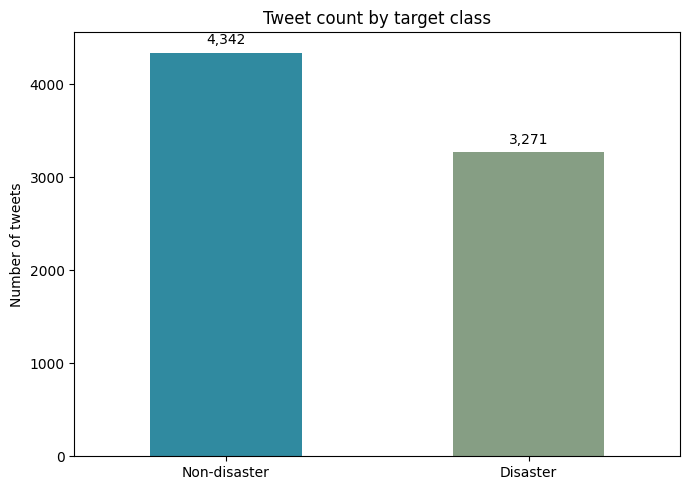

In [37]:
class_names = {0: "Non-disaster", 1: "Disaster"}
class_counts = df["target"].value_counts().reindex([0, 1], fill_value=0)
class_summary = pd.DataFrame({
    "class": [class_names[i] for i in class_counts.index],
    "count": class_counts.values,
    "percent": (class_counts / len(df) * 100).round(2).values,
})
display(class_summary)

ax = class_summary.plot.bar(
    x="class", y="count", legend=False, color=["#308AA0", "#869e84"],
    figsize=(7, 5), rot=0
)
ax.set_title("Tweet count by target class")
ax.set_xlabel("")
ax.set_ylabel("Number of tweets")
for bar, value in zip(ax.patches, class_summary["count"]):
    ax.annotate(f"{value:,}", (bar.get_x() + bar.get_width()/2, bar.get_height()),
                ha="center", va="bottom", xytext=(0, 4), textcoords="offset points")
plt.tight_layout()
plt.show()


<h2><span style="color:lightblue"><b>3. Keyword frequency by class</b></span></h2>


Top dataset keywords — Non-disaster


,keyword_clean,frequency
0,body bags,40
1,armageddon,37
2,harm,37
3,deluge,36
4,ruin,36
5,wrecked,36
6,explode,35
7,fear,35
8,siren,35
9,twister,35


Top dataset keywords — Disaster


,keyword_clean,frequency
0,derailment,39
1,outbreak,39
2,wreckage,39
3,debris,37
4,oil spill,37
5,typhoon,37
6,evacuated,32
7,rescuers,32
8,suicide bomb,32
9,suicide bombing,32


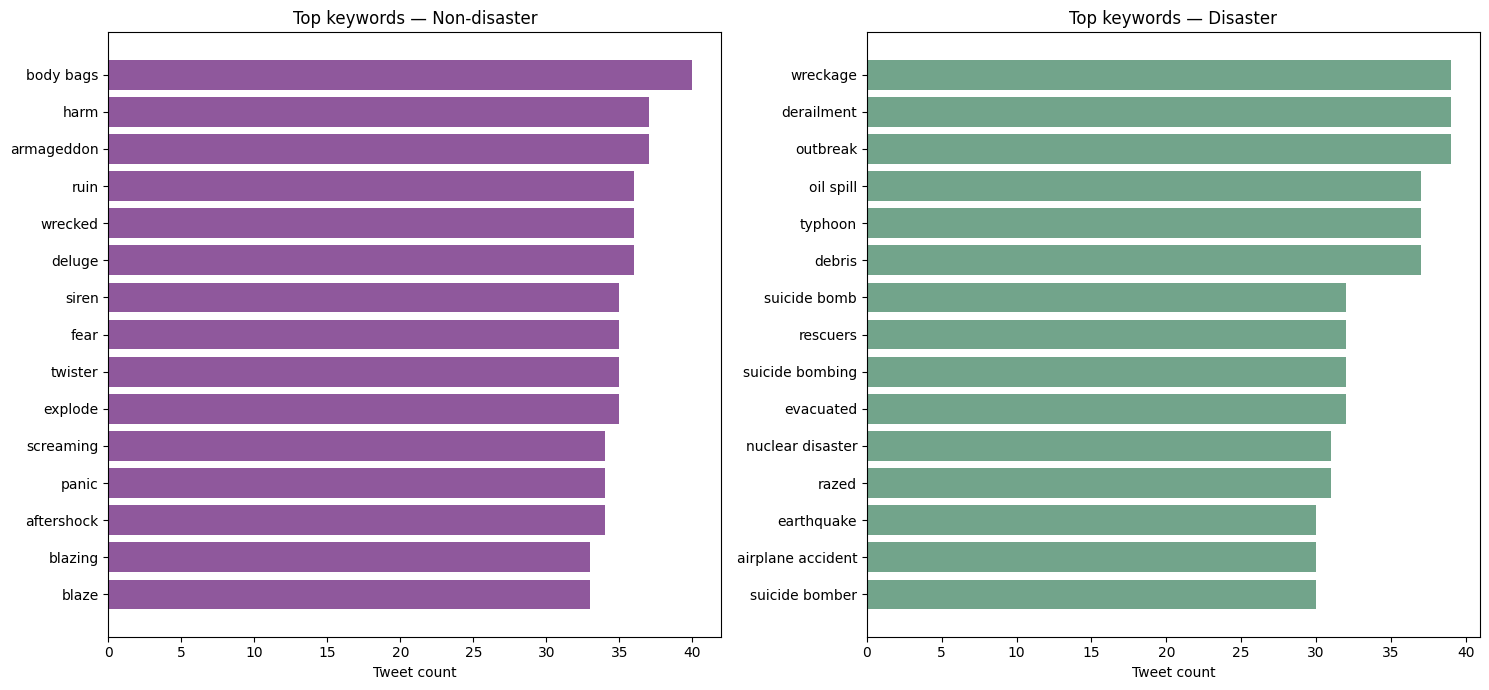

In [40]:
# The provided `keyword` field is metadata; it is distinct from words extracted from tweet text.
keyword_df = df.loc[df["keyword"].notna(), ["keyword", "target"]].copy()
keyword_df["keyword_clean"] = (
    keyword_df["keyword"].astype(str).str.replace("%20", " ", regex=False)
    .str.replace("_", " ", regex=False).str.strip().str.lower()
)
keyword_counts = (
    keyword_df.groupby(["target", "keyword_clean"]).size()
    .rename("frequency").reset_index()
)
for label, group in keyword_counts.groupby("target"):
    print(f"Top dataset keywords — {class_names[label]}")
    display(group.nlargest(15, "frequency").drop(columns="target").reset_index(drop=True))

fig, axes = plt.subplots(1, 2, figsize=(15, 7))
for ax, label in zip(axes, [0, 1]):
    top = (keyword_counts[keyword_counts["target"].eq(label)]
           .nlargest(15, "frequency").sort_values("frequency"))
    ax.barh(top["keyword_clean"], top["frequency"],
            color="#8F589C" if label == 0 else "#72a48b")
    ax.set_title(f"Top keywords — {class_names[label]}")
    ax.set_xlabel("Tweet count")
fig.tight_layout()
plt.show()


<h2><span style="color:lightblue"><b>4. Frequent words and phrases in tweet text</b></span></h2>


Top words by target class


,phrase,frequency,target
0,like,254,Non-disaster
1,just,234,Non-disaster
2,i'm,203,Non-disaster
3,new,171,Non-disaster
4,it's,129,Non-disaster
5,don't,126,Non-disaster
6,body,115,Non-disaster
7,video,96,Non-disaster
8,people,93,Non-disaster
9,love,91,Non-disaster


,phrase,frequency,target
0,news,141,Disaster
1,disaster,121,Disaster
2,suicide,112,Disaster
3,california,111,Disaster
4,police,109,Disaster
5,people,105,Disaster
6,killed,95,Disaster
7,like,94,Disaster
8,hiroshima,91,Disaster
9,just,89,Disaster


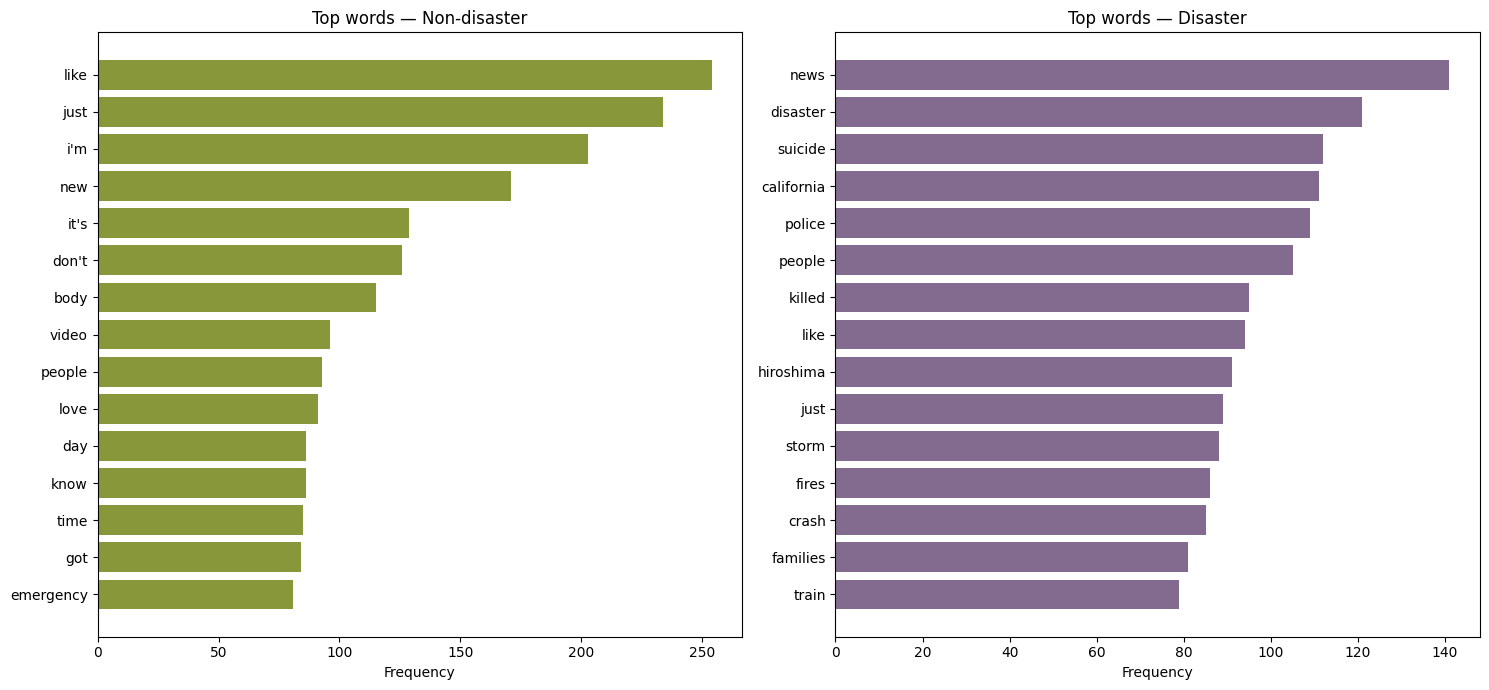

Top bigrams by target class


,phrase,frequency,target
0,cross body,39,Non-disaster
1,youtube video,36,Non-disaster
2,liked youtube,35,Non-disaster
3,gt gt,29,Non-disaster
4,body bag,27,Non-disaster
5,body bagging,24,Non-disaster
6,burning buildings,23,Non-disaster
7,body bags,22,Non-disaster
8,looks like,21,Non-disaster
9,reddit quarantine,21,Non-disaster


,phrase,frequency,target
0,suicide bomber,59,Disaster
1,northern california,41,Disaster
2,oil spill,38,Disaster
3,burning buildings,37,Disaster
4,suicide bombing,35,Disaster
5,california wildfire,34,Disaster
6,70 years,30,Disaster
7,bomber detonated,30,Disaster
8,confirmed mh370,29,Disaster
9,homes razed,29,Disaster


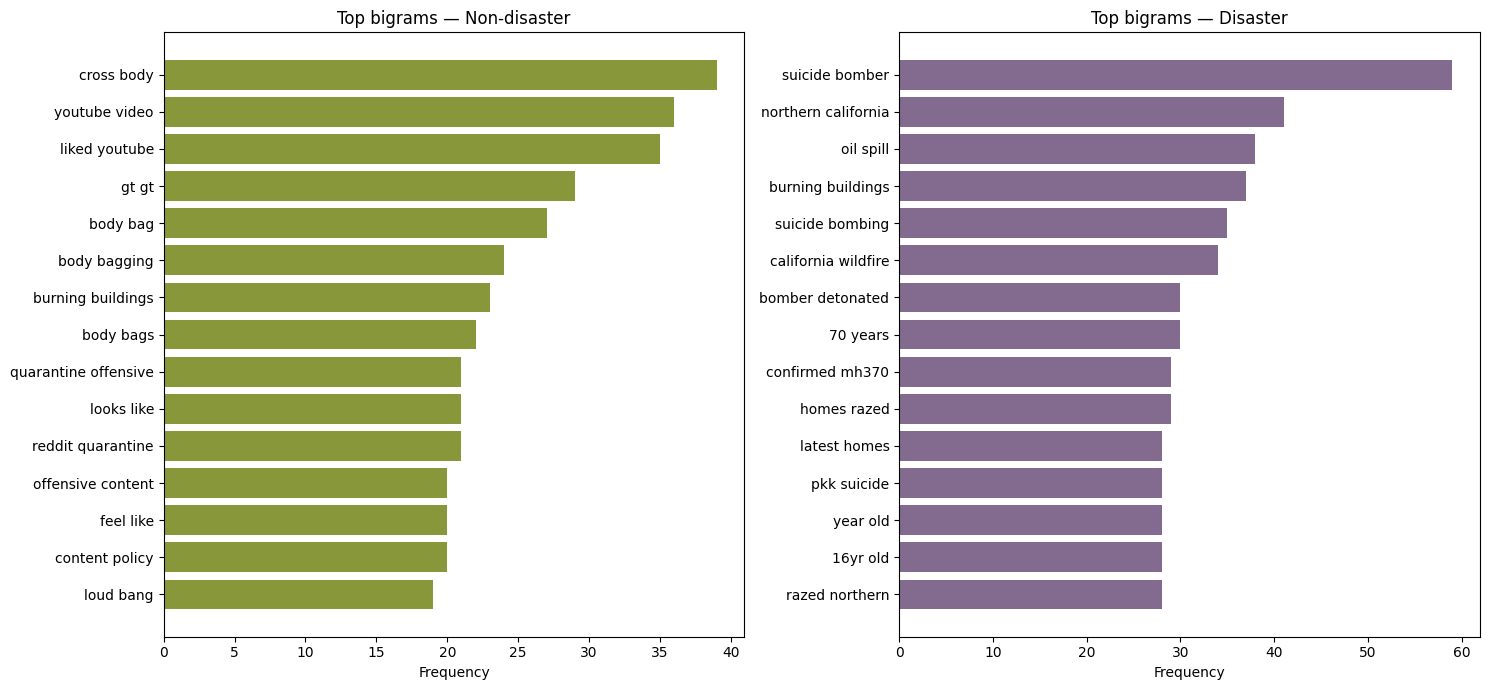

Top trigrams by target class


,phrase,frequency,target
0,liked youtube video,35,Non-disaster
1,reddit quarantine offensive,21,Non-disaster
2,quarantine offensive content,20,Non-disaster
3,cross body bag,19,Non-disaster
4,pick fan army,17,Non-disaster
5,reddit's new content,16,Non-disaster
6,new content policy,16,Non-disaster
7,stock market crash,16,Non-disaster
8,ignition knock detonation,15,Non-disaster
9,knock detonation sensor,15,Non-disaster


,phrase,frequency,target
0,suicide bomber detonated,30,Disaster
1,northern california wildfire,29,Disaster
2,latest homes razed,28,Disaster
3,homes razed northern,28,Disaster
4,pkk suicide bomber,28,Disaster
5,bomber detonated bomb,28,Disaster
6,razed northern california,27,Disaster
7,16yr old pkk,27,Disaster
8,old pkk suicide,27,Disaster
9,families sue legionnaires,26,Disaster


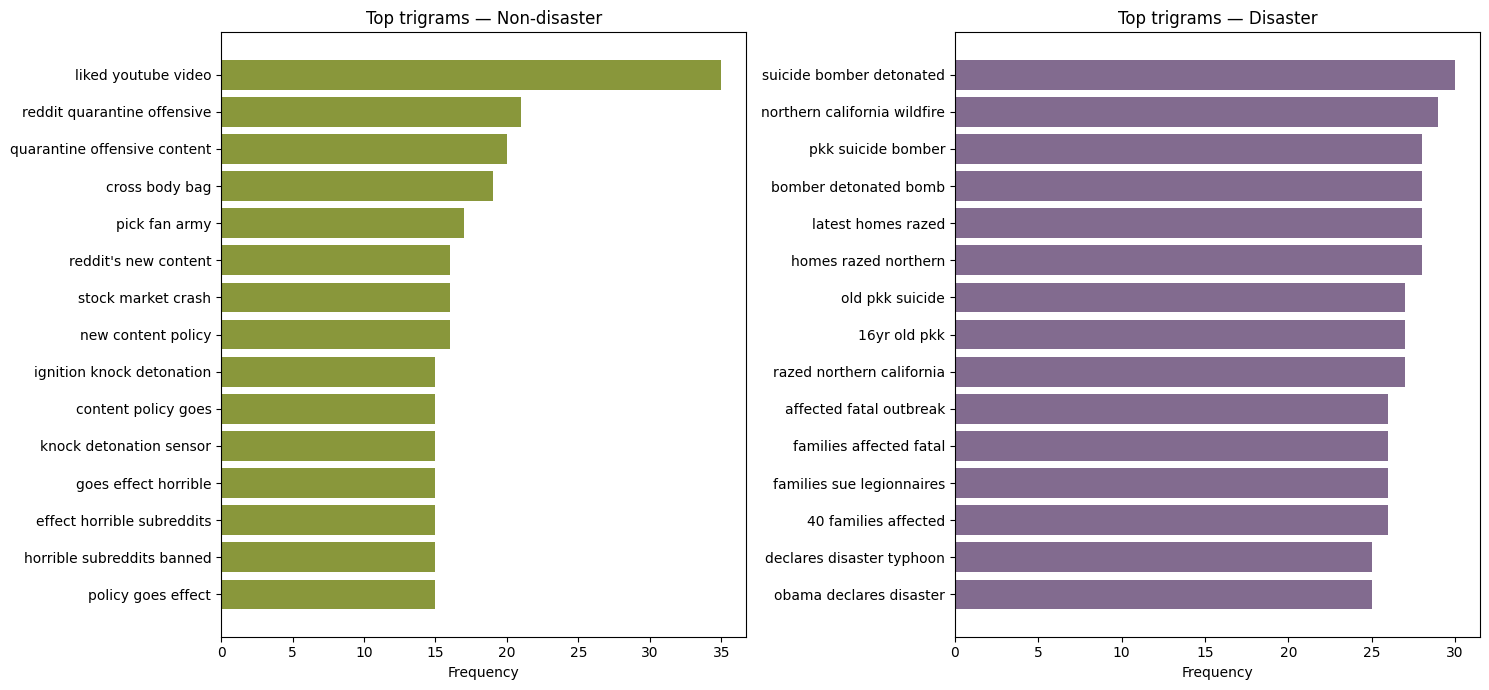

In [42]:
URL_RE = re.compile(r"https?://\S+|www\.\S+", flags=re.IGNORECASE)
TOKEN_RE = re.compile(r"[a-z0-9]+(?:['’][a-z0-9]+)?", flags=re.IGNORECASE)
STOP_WORDS = set(ENGLISH_STOP_WORDS) | {"amp", "http", "https", "co", "t", "u", "im"}

def tokenize_tweet(text):
    text = URL_RE.sub(" ", str(text).lower())
    return [token for token in TOKEN_RE.findall(text)
            if token not in STOP_WORDS and len(token) > 1]

def top_ngrams(frame, n=2, limit=15):
    counts = Counter()
    for text in frame["text"].dropna():
        tokens = tokenize_tweet(text)
        counts.update(" ".join(tokens[i:i+n]) for i in range(len(tokens)-n+1))
    return pd.DataFrame(counts.most_common(limit), columns=["phrase", "frequency"])

for n, label_name in [(1, "words"), (2, "bigrams"), (3, "trigrams")]:
    print(f"Top {label_name} by target class")
    fig, axes = plt.subplots(1, 2, figsize=(15, 7))
    for ax, label in zip(axes, [0, 1]):
        subset = df[df["target"].eq(label)]
        if n == 1:
            counts = Counter(token for text in subset["text"].dropna()
                             for token in tokenize_tweet(text))
            top = pd.DataFrame(counts.most_common(15), columns=["phrase", "frequency"])
        else:
            top = top_ngrams(subset, n=n, limit=15)
        display(top.assign(target=class_names[label]))
        top = top.sort_values("frequency")
        ax.barh(top["phrase"], top["frequency"],
                color="#89973B" if label == 0 else "#826b8f")
        ax.set_title(f"Top {label_name} — {class_names[label]}")
        ax.set_xlabel("Frequency")
    fig.tight_layout()
    plt.show()


In [53]:
from IPython.display import HTML, display

def extract_eda_keywords(text):
    """Return lowercase alphanumeric tokens from a tweet."""
    if not isinstance(text, str):
        return []

    tokens = []
    current_token = []

    for character in text.lower():
        if character.isalnum():
            current_token.append(character)
        elif current_token:
            tokens.append("".join(current_token))
            current_token = []

    if current_token:
        tokens.append("".join(current_token))

    return tokens


def get_phrase_frequency(text_series, n=2, top_n=20):
    """
    Calculate the most frequent multi-word expressions.
    n = 2  -> Bigrams
    n = 3  -> Trigrams
    """
    phrase_counter = Counter()
    for tweet in text_series:
        tokens = extract_eda_keywords(tweet)
        if len(tokens) >= n:

            ngrams = zip(
                *[tokens[i:] for i in range(n)]
            )

            phrases = [
                " ".join(gram)
                for gram in ngrams
            ]

            phrase_counter.update(phrases)

    result = pd.DataFrame(
        phrase_counter.most_common(top_n),
        columns=["Phrase", "Frequency"]
    )
    result.index = range(1, len(result) + 1)
    return result

phrase_source = pd.concat(
    [train_df, test_df],
    ignore_index=True
)
disaster_tweets = phrase_source.loc[
    phrase_source["target"] == 1,
    "text"
].dropna()
non_disaster_tweets = phrase_source.loc[
    phrase_source["target"] == 0,
    "text"
].dropna()

TOP_N = 20
disaster_bigrams = get_phrase_frequency(
    disaster_tweets,
    n=2,
    top_n=TOP_N
)
non_disaster_bigrams = get_phrase_frequency(
    non_disaster_tweets,
    n=2,
    top_n=TOP_N
)
disaster_trigrams = get_phrase_frequency(
    disaster_tweets,
    n=3,
    top_n=TOP_N
)
non_disaster_trigrams = get_phrase_frequency(
    non_disaster_tweets,
    n=3,
    top_n=TOP_N
)
top_disaster_bigram = (
    disaster_bigrams.iloc[0]["Phrase"]
    if len(disaster_bigrams)
    else "N/A"
)
top_disaster_bigram_freq = (
    int(disaster_bigrams.iloc[0]["Frequency"])
    if len(disaster_bigrams)
    else 0
)
top_non_disaster_bigram = (
    non_disaster_bigrams.iloc[0]["Phrase"]
    if len(non_disaster_bigrams)
    else "N/A"
)
top_non_disaster_bigram_freq = (
    int(non_disaster_bigrams.iloc[0]["Frequency"])
    if len(non_disaster_bigrams)
    else 0
)
top_disaster_trigram = (
    disaster_trigrams.iloc[0]["Phrase"]
    if len(disaster_trigrams)
    else "N/A"
)
top_disaster_trigram_freq = (
    int(disaster_trigrams.iloc[0]["Frequency"])
    if len(disaster_trigrams)
    else 0
)
top_non_disaster_trigram = (
    non_disaster_trigrams.iloc[0]["Phrase"]
    if len(non_disaster_trigrams)
    else "N/A"
)
top_non_disaster_trigram_freq = (
    int(non_disaster_trigrams.iloc[0]["Frequency"])
    if len(non_disaster_trigrams)
    else 0
)

def phrase_table_html(data, bar_color):
    if data.empty:
        return """
        <div style="
            padding:20px;
            text-align:center;
            color:#786A71;">
            No phrase data available.
        </div>
        """
    max_frequency = data["Frequency"].max()
    rows = ""
    for rank, (_, row) in enumerate(
        data.iterrows(),
        start=1
    ):

        relative_width = (
            row["Frequency"] /
            max_frequency *
            100
        )
        rows += f"""
        <tr>
            <td class="rank">
                {rank}
            </td>
            <td class="phrase">
                {row["Phrase"]}
            </td>
            <td class="frequency">
                {int(row["Frequency"]):,}
            </td>
            <td class="visual-cell">
                <div class="bar-track">
                    <div
                        class="bar-fill"
                        style="
                            width:{relative_width:.2f}%;
                            background:{bar_color};
                        ">
                    </div>
                </div>
            </td>
        </tr>
        """
    return f"""
    <table class="phrase-table">
        <thead>
            <tr>
                <th>Rank</th>
                <th>Phrase</th>
                <th>Frequency</th>
                <th>Relative Frequency</th>
            </tr>
        </thead>
        <tbody>
            {rows}
        </tbody>
    </table>
    """

phrase_dashboard_id = "phrase-frequency-dashboard"

phrase_dashboard_html = f"""

<div id="{phrase_dashboard_id}" class="phrase-dashboard">

<style>


/* ==========================================================
   DASHBOARD
========================================================== */

#{phrase_dashboard_id} {{

    width: 100%;

    box-sizing: border-box;

    font-family:
        -apple-system,
        BlinkMacSystemFont,
        "Segoe UI",
        Arial,
        sans-serif;

    color: #4F474B;
}}


/* ==========================================================
   HEADER
========================================================== */

#{phrase_dashboard_id} .header {{

    padding: 29px 31px;

    background:
        linear-gradient(
            135deg,
            #3D2030 0%,
            #593148 55%,
            #75465B 100%
        );

    border-radius: 14px 14px 0 0;

    border-bottom:
        4px solid #D1A978;
}}


#{phrase_dashboard_id} .eyebrow {{

    margin: 0 0 7px;

    color: #E7C99F;

    font-size: 10px;

    font-weight: 700;

    letter-spacing: 2px;

    text-transform: uppercase;
}}


#{phrase_dashboard_id} .title {{

    margin: 0;

    color: #FFFFFF;

    font-family:
        Georgia,
        "Times New Roman",
        serif;

    font-size: 27px;

    font-weight: 500;
}}


#{phrase_dashboard_id} .subtitle {{

    margin: 9px 0 0;

    color: #EBDDE4;

    font-size: 13.5px;

    line-height: 1.7;
}}


/* ==========================================================
   NAVIGATION
========================================================== */

#{phrase_dashboard_id} .tabs {{

    display: flex;

    gap: 5px;

    padding: 12px;

    background: #F6EFF2;

    border-left:
        1px solid #E5D8DE;

    border-right:
        1px solid #E5D8DE;

    overflow-x: auto;
}}


#{phrase_dashboard_id} .tab-btn {{

    min-height: 42px;

    padding: 10px 16px;

    border:
        1px solid transparent;

    border-radius: 8px;

    background: transparent;

    color: #6A5861;

    font-size: 12px;

    font-weight: 600;

    cursor: pointer;

    white-space: nowrap;

    transition: 0.2s ease;
}}


#{phrase_dashboard_id} .tab-btn:hover {{

    # background: #ECE0E6;
}}


#{phrase_dashboard_id} .tab-btn.active {{

    background: #563247;

    color: #FFFFFF;
}}


/* ==========================================================
   CONTENT
========================================================== */

#{phrase_dashboard_id} .content {{

    padding: 27px;

    background: #FFFFFF;

    border-left:
        1px solid #E5D8DE;

    border-right:
        1px solid #E5D8DE;

    border-bottom:
        1px solid #E5D8DE;

    border-radius:
        0 0 14px 14px;
}}


#{phrase_dashboard_id} .panel {{

    display: none;
}}


#{phrase_dashboard_id} .panel.active {{

    display: block;
}}


/* ==========================================================
   SECTION
========================================================== */

#{phrase_dashboard_id} .section-label {{

    margin: 0 0 5px;

    color: #A36F83;

    font-size: 10px;

    font-weight: 700;

    letter-spacing: 1.8px;

    text-transform: uppercase;
}}


#{phrase_dashboard_id} .section-title {{

    margin: 0 0 8px;

    color: #4B2638;

    font-family:
        Georgia,
        "Times New Roman",
        serif;

    font-size: 22px;

    font-weight: 500;
}}


#{phrase_dashboard_id} .section-text {{

    margin: 0 0 22px;

    color: #73676D;

    font-size: 13.5px;

    line-height: 1.75;
}}


/* ==========================================================
   KPI CARDS
========================================================== */

#{phrase_dashboard_id} .kpi-grid {{

    display: grid;

    grid-template-columns:
        repeat(4, minmax(150px, 1fr));

    gap: 13px;

    margin-bottom: 24px;
}}


#{phrase_dashboard_id} .kpi-card {{

    padding: 18px;

    background:
        linear-gradient(
            135deg,
            #FCF9FA,
            #F5EDF1
        );

    border:
        1px solid #E8DDE2;

    border-top:
        3px solid #D1A978;

    border-radius: 9px;
}}


#{phrase_dashboard_id} .kpi-label {{

    color: #8D7681;

    font-size: 9px;

    font-weight: 700;

    letter-spacing: 1.2px;

    text-transform: uppercase;
}}


#{phrase_dashboard_id} .kpi-value {{

    margin-top: 7px;

    color: #4B2638;

    font-family:
        Georgia,
        "Times New Roman",
        serif;

    font-size: 17px;

    font-weight: 600;

    line-height: 1.35;
}}


#{phrase_dashboard_id} .kpi-note {{

    margin-top: 5px;

    color: #8A7C83;

    font-size: 10.5px;
}}


/* ==========================================================
   TABLE
========================================================== */

#{phrase_dashboard_id} .table-wrap {{

    width: 100%;

    overflow-x: auto;

    border:
        1px solid #E7DDE1;

    border-radius: 9px;
}}


#{phrase_dashboard_id} table {{

    width: 100%;

    min-width: 650px;

    border-collapse: collapse;
}}


#{phrase_dashboard_id} th {{

    padding: 11px 13px;

    background: #563247;

    color: #FFFFFF;

    font-size: 11.5px;

    font-weight: 600;

    text-align: left;

    border-bottom:
        2px solid #D1A978;
}}


#{phrase_dashboard_id} td {{

    padding: 10px 13px;

    color: #51494D;

    font-size: 12px;

    border-bottom:
        1px solid #EEE5E9;
}}


#{phrase_dashboard_id}
tbody tr:nth-child(even) {{

    background: #FAF6F8;
}}


#{phrase_dashboard_id}
tbody tr:hover {{

    background: #F3E8ED;
}}


#{phrase_dashboard_id} .rank {{

    width: 55px;

    text-align: center;

    color: #9A828D;

    font-weight: 600;
}}


#{phrase_dashboard_id} .phrase {{

    color: #5A3043;

    font-weight: 600;
}}


#{phrase_dashboard_id} .frequency {{

    width: 95px;

    text-align: center;

    font-variant-numeric:
        tabular-nums;
}}


#{phrase_dashboard_id} .visual-cell {{

    width: 36%;
}}


#{phrase_dashboard_id} .bar-track {{

    width: 100%;

    height: 8px;

    background: #EEE5E9;

    border-radius: 10px;

    overflow: hidden;
}}


#{phrase_dashboard_id} .bar-fill {{

    height: 100%;

    border-radius: 10px;
}}


/* ==========================================================
   INFORMATION BOX
========================================================== */

#{phrase_dashboard_id} .info-box {{

    padding: 21px 23px;

    background: #F8F3F5;

    border-left:
        4px solid #7A3E57;

    border-radius:
        0 8px 8px 0;

    color: #62575C;

    font-size: 13.5px;

    line-height: 1.85;
}}


/* ==========================================================
   RESPONSIVE
========================================================== */

@media (max-width: 760px) {{

    #{phrase_dashboard_id} .kpi-grid {{

        grid-template-columns:
            repeat(2, 1fr);
    }}
}}


@media (max-width: 480px) {{

    #{phrase_dashboard_id} .kpi-grid {{

        grid-template-columns: 1fr;
    }}
}}

</style>



<!-- ========================================================
     HEADER
======================================================== -->

<div class="header">

    <p class="eyebrow">
        Task 1 · Textual Exploration
    </p>

    <h2 class="title">
        Phrase Frequency Intelligence
    </h2>

    <p class="subtitle">
        Interactive analysis of frequently occurring
        two-word and three-word expressions across
        disaster and non-disaster tweets.
    </p>

</div>



<!-- ========================================================
     TABS
======================================================== -->

<div class="tabs">

    <button
        type="button"
        class="tab-btn active"
        data-target="overview">

        Overview

    </button>


    <button
        type="button"
        class="tab-btn"
        data-target="disaster-bigrams">

        Disaster Bigrams

    </button>


    <button
        type="button"
        class="tab-btn"
        data-target="non-disaster-bigrams">

        Non-Disaster Bigrams

    </button>


    <button
        type="button"
        class="tab-btn"
        data-target="disaster-trigrams">

        Disaster Trigrams

    </button>


    <button
        type="button"
        class="tab-btn"
        data-target="non-disaster-trigrams">

        Non-Disaster Trigrams

    </button>

</div>



<!-- ========================================================
     CONTENT
======================================================== -->

<div class="content">


<!-- OVERVIEW ------------------------------------------------ -->

<div
    class="panel active"
    data-panel="overview">

    <p class="section-label">
        Phrase Overview
    </p>

    <h3 class="section-title">
        Contextual Language Summary
    </h3>

    <p class="section-text">
        Phrase-level analysis captures contextual information
        that individual keywords cannot represent by examining
        recurring two-word and three-word combinations.
    </p>


    <div class="kpi-grid">


        <div class="kpi-card">

            <div class="kpi-label">
                Top Disaster Bigram
            </div>

            <div class="kpi-value">
                {top_disaster_bigram}
            </div>

            <div class="kpi-note">
                {top_disaster_bigram_freq:,}
                occurrences
            </div>

        </div>


        <div class="kpi-card">

            <div class="kpi-label">
                Top Non-Disaster Bigram
            </div>

            <div class="kpi-value">
                {top_non_disaster_bigram}
            </div>

            <div class="kpi-note">
                {top_non_disaster_bigram_freq:,}
                occurrences
            </div>

        </div>


        <div class="kpi-card">

            <div class="kpi-label">
                Top Disaster Trigram
            </div>

            <div class="kpi-value">
                {top_disaster_trigram}
            </div>

            <div class="kpi-note">
                {top_disaster_trigram_freq:,}
                occurrences
            </div>

        </div>


        <div class="kpi-card">

            <div class="kpi-label">
                Top Non-Disaster Trigram
            </div>

            <div class="kpi-value">
                {top_non_disaster_trigram}
            </div>

            <div class="kpi-note">
                {top_non_disaster_trigram_freq:,}
                occurrences
            </div>

        </div>

    </div>


    <div class="info-box">

        <strong style="color:#4B2638;">
            Bigram analysis
        </strong>

        captures frequently occurring two-word combinations,
        while

        <strong style="color:#4B2638;">
            trigram analysis
        </strong>

        examines three-word expressions that provide greater
        contextual information.

        <br><br>

        Use the tabs above to inspect each phrase group
        independently.

    </div>

</div>



<!-- DISASTER BIGRAMS --------------------------------------- -->

<div
    class="panel"
    data-panel="disaster-bigrams">

    <p class="section-label">
        Disaster Language
    </p>

    <h3 class="section-title">
        Most Frequent Disaster Bigrams
    </h3>

    <p class="section-text">
        Most frequently occurring two-word expressions
        within tweets labelled as genuine disasters.
    </p>

    <div class="table-wrap">

        {phrase_table_html(
            disaster_bigrams,
            "#6C9C70"
        )}

    </div>

</div>



<!-- NON-DISASTER BIGRAMS ----------------------------------- -->

<div
    class="panel"
    data-panel="non-disaster-bigrams">

    <p class="section-label">
        Non-Disaster Language
    </p>

    <h3 class="section-title">
        Most Frequent Non-Disaster Bigrams
    </h3>

    <p class="section-text">
        Frequently recurring two-word combinations found
        within tweets classified as non-disaster content.
    </p>

    <div class="table-wrap">

        {phrase_table_html(
            non_disaster_bigrams,
            "#79916A"
        )}

    </div>

</div>



<!-- DISASTER TRIGRAMS -------------------------------------- -->

<div
    class="panel"
    data-panel="disaster-trigrams">

    <p class="section-label">
        Disaster Context
    </p>

    <h3 class="section-title">
        Most Frequent Disaster Trigrams
    </h3>

    <p class="section-text">
        Three-word expressions provide additional contextual
        information about how genuine disaster events are
        described.
    </p>

    <div class="table-wrap">

        {phrase_table_html(
            disaster_trigrams,
            "#6C8A6F"
        )}

    </div>

</div>



<!-- NON-DISASTER TRIGRAMS ---------------------------------- -->

<div
    class="panel"
    data-panel="non-disaster-trigrams">

    <p class="section-label">
        Non-Disaster Context
    </p>

    <h3 class="section-title">
        Most Frequent Non-Disaster Trigrams
    </h3>

    <p class="section-text">
        These three-word expressions represent frequently
        occurring contextual patterns within non-disaster
        tweets.
    </p>

    <div class="table-wrap">

        {phrase_table_html(
            non_disaster_trigrams,
            "#699193"
        )}

    </div>

</div>


</div>



<!-- ========================================================
     INTERACTION
======================================================== -->

<script>

(() => {{

    const root =
        document.getElementById(
            "{phrase_dashboard_id}"
        );
    if (!root || root.dataset.ready === "1")
        return;
    root.dataset.ready = "1";
    const buttons =
        root.querySelectorAll(
            ".tab-btn"
        );
    const panels =
        root.querySelectorAll(
            ".panel"
        );
    buttons.forEach(button => {{
        button.addEventListener(
            "click",
            () => {{
                const target =
                    button.dataset.target;
                buttons.forEach(btn =>
                    btn.classList.remove(
                        "active"
                    )
                );
                panels.forEach(panel =>
                    panel.classList.remove(
                        "active"
                    )
                );
                button.classList.add(
                    "active"
                );
                const selected =
                    root.querySelector(
                        `[data-panel="${{target}}"]`
                    );
                if (selected) {{
                    selected.classList.add(
                        "active"
                    );
                }}
            }}
        );
    }});
}})();
</script>
</div>
"""
display(
    HTML(
        phrase_dashboard_html
    )
)

Rank,Phrase,Frequency,Relative Frequency
1,t co,"2,517",
2,http t,"2,382",
3,in the,145,
4,https t,135,
5,of the,119,
6,û http,112,
7,it s,59,
8,suicide bomber,59,
9,on the,51,
10,in a,50,


<h2><span style="color:lightblue"><b>5. Exploration notes</b></span></h2>


- Use the class table and chart to describe class balance; do not rely on accuracy alone if the classes differ materially.
- Compare class-specific keyword and phrase rankings. A frequent term is a useful signal, not proof that a tweet describes a real event: terms can be figurative or ambiguous.
- The `keyword` column is supplied metadata. The word and phrase analysis is derived separately from `text` and removes URLs and common stop words.
- The brief's stated sample size (10,000) does not match the supplied CSV (7,613 rows); confirm whether another file is expected before claiming results for 10,000 tweets.


<h2><span style="color:lightblue"><b>Insights</b></span></h2>


The supplied data has **7,613** rows and five fields. It contains **4,342 non-disaster tweets (57.0%)** and **3,271 disaster tweets (43.0%)**, with no duplicate rows or missing tweet text/labels. `keyword` is missing for 61 rows and `location` for 2,534, so neither should be treated as a complete feature. The class split is reasonably balanced, but precision and recall remain more informative than accuracy alone. Class-specific phrases such as “suicide bomber” and “northern california” appear among disaster tweets; phrase frequency is only a clue, since context and figurative usage still matter.


<h2><span style="color:lightblue"><b>Interpretation</b></span></h2>



The exploratory analysis indicates that disaster classification
cannot rely solely on the presence of isolated disaster-related
terms. Similar vocabulary may appear in both target classes, while
multi-word expressions provide additional contextual information.
Consequently, subsequent preprocessing and feature engineering
should preserve meaningful textual context rather than applying
excessively aggressive text removal.



The next stage will therefore focus on systematic text preparation,
including cleaning, normalization and tokenization, while retaining
the linguistic information required for reliable classification.



The dataset is suitable for a first binary-classification baseline. The brief’s 10,000-row count does not match the supplied file and should be clarified before presenting the results as representative of 10,000 tweets.

<h2><span style="color:lightblue"><b>6. Text cleaning and tokenization</b></span></h2>


Keep a copy of each original tweet, remove URLs and punctuation from a separate modeling text field, normalize whitespace and case, then tokenize the cleaned text. This is a lightweight baseline preprocessing step; later modeling can compare alternatives such as preserving hashtags or negation punctuation.

In [54]:
def clean_tweet(text):
    text = URL_RE.sub(" ", str(text))
    text = re.sub(r"<[^>]+>", " ", text)       # HTML fragments
    text = text.lower()
    text = re.sub(r"[^a-z0-9\s]", " ", text) # punctuation and special characters
    return re.sub(r"\s+", " ", text).strip()

prepared = df.copy(deep=True)
prepared["original_text"] = prepared["text"]
prepared["clean_text"] = prepared["text"].map(clean_tweet)
prepared["tokens"] = prepared["clean_text"].map(str.split)
prepared["target"] = prepared["target"].map({0: 0, 1: 1}).astype("int8")

assert prepared["target"].isin([0, 1]).all()
assert prepared["clean_text"].notna().all()
assert prepared["tokens"].map(lambda tokens: isinstance(tokens, list)).all()

display(prepared[["original_text", "clean_text", "tokens", "target"]].head(20))
print("Rows retained:", f"{len(prepared):,}")
print("Target labels:", sorted(prepared["target"].unique().tolist()))
print("Empty token lists:", int(prepared["tokens"].map(len).eq(0).sum()))


,original_text,clean_text,tokens,target
0,Our Deeds are the Reason of this #earthquake M...,our deeds are the reason of this earthquake ma...,"[our, deeds, are, the, reason, of, this, earth...",1
1,Forest fire near La Ronge Sask. Canada,forest fire near la ronge sask canada,"[forest, fire, near, la, ronge, sask, canada]",1
2,All residents asked to 'shelter in place' are ...,all residents asked to shelter in place are be...,"[all, residents, asked, to, shelter, in, place...",1
3,"13,000 people receive #wildfires evacuation or...",13 000 people receive wildfires evacuation ord...,"[13, 000, people, receive, wildfires, evacuati...",1
4,Just got sent this photo from Ruby #Alaska as ...,just got sent this photo from ruby alaska as s...,"[just, got, sent, this, photo, from, ruby, ala...",1
5,#RockyFire Update => California Hwy. 20 closed...,rockyfire update california hwy 20 closed in b...,"[rockyfire, update, california, hwy, 20, close...",1
6,#flood #disaster Heavy rain causes flash flood...,flood disaster heavy rain causes flash floodin...,"[flood, disaster, heavy, rain, causes, flash, ...",1
7,I'm on top of the hill and I can see a fire in...,i m on top of the hill and i can see a fire in...,"[i, m, on, top, of, the, hill, and, i, can, se...",1
8,There's an emergency evacuation happening now ...,there s an emergency evacuation happening now ...,"[there, s, an, emergency, evacuation, happenin...",1
9,I'm afraid that the tornado is coming to our a...,i m afraid that the tornado is coming to our area,"[i, m, afraid, that, the, tornado, is, coming,...",1


Rows retained: 7,613
Target labels: [0, 1]
Empty token lists: 0


<h2><span style="color:lightblue"><b>7. Stratified train/test split</b></span></h2>


Create an 80/20 split with a fixed random seed and stratify by the target. Stratification preserves approximately the same disaster/non-disaster proportions in both subsets. The split is made at the tweet-row level, before any model vocabulary or TF-IDF features are learned.

In [8]:
train_df, test_df = train_test_split(
    prepared,
    test_size=0.20,
    random_state=42,
    stratify=prepared["target"],
)
train_df = train_df.reset_index(drop=True)
test_df = test_df.reset_index(drop=True)

assert set(train_df["id"]).isdisjoint(set(test_df["id"]))
assert len(train_df) + len(test_df) == len(prepared)

split_summary = pd.DataFrame({
    "split": ["Train", "Test", "Total"],
    "rows": [len(train_df), len(test_df), len(prepared)],
    "disaster_tweets": [
        int(train_df["target"].sum()),
        int(test_df["target"].sum()),
        int(prepared["target"].sum()),
    ],
})
split_summary["disaster_pct"] = (
    split_summary["disaster_tweets"] / split_summary["rows"] * 100
).round(2)
display(split_summary)


,split,rows,disaster_tweets,disaster_pct
0,Train,6090,2617,42.97
1,Test,1523,654,42.94
2,Total,7613,3271,42.97


<h2><span style="color:lightblue"><b>8. Save prepared splits</b></span></h2>


Save the reproducible split tables under `data/processed/`. The `tokens` list is stored as a space-separated `tokens_text` column in CSV for portability; `clean_text` is also retained. `original_text` stays available for review.

In [9]:
processed_dir = Path("data") / "processed"
processed_dir.mkdir(parents=True, exist_ok=True)

export_columns = [
    "id", "keyword", "location", "original_text", "clean_text",
    "tokens_text", "target"
]
for split_df, filename in [
    (train_df, "disaster_tweets_train.csv"),
    (test_df, "disaster_tweets_test.csv"),
]:
    export_df = split_df.copy()
    export_df["tokens_text"] = export_df["tokens"].map(" ".join)
    export_df[export_columns].to_csv(processed_dir / filename, index=False)
    print(f"Saved {len(export_df):,} rows: {processed_dir / filename}")


Saved 6,090 rows: data\processed\disaster_tweets_train.csv
Saved 1,523 rows: data\processed\disaster_tweets_test.csv


<h2><span style="color:lightblue"><b>Insights</b></span></h2>


Text is normalized into lowercase tokens after removing URLs, punctuation, and special characters, while the original tweet is retained for traceability. Target labels are validated as 0/1. A fixed-seed, stratified 80/20 split creates **6,090 training** and **1,523 test** rows, preserving class proportions and keeping tweet IDs disjoint.


<h2><span style="color:lightblue"><b>Interpretation</b></span></h2>


**Interpretation:** the split is repeatable and appropriate for model development. Removing punctuation and URLs simplifies the baseline, but may discard expressive or contextual signals; the original text remains available for future preprocessing comparisons.

<h2><span style="color:lightblue"><b>Part 2: Feature Engineering and Model Selection</b></span></h2>


Build three complementary feature groups: word and character TF-IDF from the cleaned text, tweet structure signals from the original text, and transparent lexicon-based sentiment signals. Fit every learned text transform on the training split only, then apply it unchanged to the test split to prevent vocabulary leakage.

<h2><span style="color:lightblue"><b>2.1 Engineer tweet-level features</b></span></h2>


The structural features include character and token counts, average token length, hashtag and mention counts, URL count, punctuation counts, and uppercase ratio. Sentiment is represented with small positive and negative word lexicons so this notebook runs without downloading a separate model. These sentiment scores are lightweight features and should not be interpreted as a nuanced understanding of sarcasm or context.

In [10]:
import numpy as np
from scipy.sparse import hstack, save_npz
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.preprocessing import StandardScaler
import joblib

POSITIVE_WORDS = set("good great excellent happy love loved best wonderful amazing thank thanks safe success successful hope hopeful beautiful brave calm joy joyful pleased proud relief relieved strong support supportive win wins welcome".split())
NEGATIVE_WORDS = set("bad terrible awful sad hate hated worst horrible danger dangerous injured dead death killed kill fear afraid tragic tragedy emergency disaster damage damaged destroy destroyed hurt pain fire flood storm earthquake explosion crash attack evacuate evacuation missing suffer suffering".split())

HASHTAG_RE = re.compile(r"(?<!\w)#\w+")
MENTION_RE = re.compile(r"(?<!\w)@[A-Za-z0-9_]+")
URL_COUNT_RE = re.compile(r"https?://\S+|www\.\S+", flags=re.IGNORECASE)

def extract_structural_features(frame):
    original = frame["original_text"].fillna("").astype(str)
    cleaned = frame["clean_text"].fillna("").astype(str)
    token_lists = frame["tokens"]
    records = []
    for raw, clean, tokens in zip(original, cleaned, token_lists):
        lower_tokens = [t.lower() for t in tokens]
        pos = sum(t in POSITIVE_WORDS for t in lower_tokens)
        neg = sum(t in NEGATIVE_WORDS for t in lower_tokens)
        token_count = len(tokens)
        records.append({
            "char_count": len(raw),
            "token_count": token_count,
            "mean_token_length": (sum(map(len, tokens)) / token_count) if token_count else 0.0,
            "hashtag_count": len(HASHTAG_RE.findall(raw)),
            "mention_count": len(MENTION_RE.findall(raw)),
            "url_count": len(URL_COUNT_RE.findall(raw)),
            "exclamation_count": raw.count("!"),
            "question_count": raw.count("?"),
            "uppercase_ratio": (sum(ch.isupper() for ch in raw) / len(raw)) if raw else 0.0,
            "positive_word_count": pos,
            "negative_word_count": neg,
            "sentiment_polarity": ((pos - neg) / token_count) if token_count else 0.0,
        })
    return pd.DataFrame(records, index=frame.index)

train_numeric = extract_structural_features(train_df)
test_numeric = extract_structural_features(test_df)
numeric_feature_names = train_numeric.columns.tolist()
display(train_numeric.describe().T.round(3))


,count,mean,std,min,25%,50%,75%,max
char_count,6090.0,101.052,33.741,7.000,77.000,107.000,133.000,157.000
token_count,6090.0,14.586,6.067,1.000,10.000,14.000,19.000,34.000
mean_token_length,6090.0,4.914,1.019,2.000,4.211,4.818,5.462,11.500
hashtag_count,6090.0,0.437,1.101,0.000,0.000,0.000,0.000,13.000
mention_count,6090.0,0.348,0.702,0.000,0.000,0.000,1.000,8.000
url_count,6090.0,0.623,0.668,0.000,0.000,1.000,1.000,4.000
exclamation_count,6090.0,0.156,0.616,0.000,0.000,0.000,0.000,12.000
question_count,6090.0,0.400,1.808,0.000,0.000,0.000,0.000,54.000
uppercase_ratio,6090.0,0.100,0.108,0.000,0.038,0.074,0.126,0.895
positive_word_count,6090.0,0.087,0.314,0.000,0.000,0.000,0.000,4.000


<h2><span style="color:lightblue"><b>2.2 Fit word and character TF-IDF</b></span></h2>


Word unigrams and bigrams capture short phrases; character 3–5 grams help represent spelling variants, hashtags, and informal forms. `min_df` and `max_features` limit rare and very large vocabulary entries. Both vectorizers are fit on training tweets only.

In [11]:
word_vectorizer = TfidfVectorizer(
    ngram_range=(1, 2), min_df=2, max_features=50000,
    sublinear_tf=True, strip_accents="unicode", dtype=np.float32
)
char_vectorizer = TfidfVectorizer(
    analyzer="char", ngram_range=(3, 5), min_df=2, max_features=30000,
    sublinear_tf=True, dtype=np.float32
)

X_train_word = word_vectorizer.fit_transform(train_df["clean_text"])
X_test_word = word_vectorizer.transform(test_df["clean_text"])
X_train_char = char_vectorizer.fit_transform(train_df["clean_text"])
X_test_char = char_vectorizer.transform(test_df["clean_text"])
print("Word TF-IDF:", X_train_word.shape, "train /", X_test_word.shape, "test")
print("Character TF-IDF:", X_train_char.shape, "train /", X_test_char.shape, "test")


Word TF-IDF: (6090, 14227) train / (1523, 14227) test
Character TF-IDF: (6090, 30000) train / (1523, 30000) test


<h2><span style="color:lightblue"><b>2.3 Scale numeric features and assemble matrices</b></span></h2>


The numeric feature scaler is also fit on training rows only. The resulting sparse matrices combine word TF-IDF, character TF-IDF, and scaled numeric/sentiment signals for later model selection.

In [12]:
numeric_scaler = StandardScaler(with_mean=False)
X_train_numeric = numeric_scaler.fit_transform(train_numeric).astype(np.float32)
X_test_numeric = numeric_scaler.transform(test_numeric).astype(np.float32)

X_train_features = hstack(
    [X_train_word, X_train_char, X_train_numeric], format="csr", dtype=np.float32
)
X_test_features = hstack(
    [X_test_word, X_test_char, X_test_numeric], format="csr", dtype=np.float32
)
y_train = train_df["target"].to_numpy(dtype=np.int8)
y_test = test_df["target"].to_numpy(dtype=np.int8)

feature_group_summary = pd.DataFrame({
    "feature_group": ["word TF-IDF", "character TF-IDF", "numeric + sentiment", "combined"],
    "features": [X_train_word.shape[1], X_train_char.shape[1], X_train_numeric.shape[1], X_train_features.shape[1]],
    "train_nonzero": [X_train_word.nnz, X_train_char.nnz, int(np.count_nonzero(X_train_numeric)), X_train_features.nnz],
})
display(feature_group_summary)
print("Train matrix:", X_train_features.shape, "Test matrix:", X_test_features.shape)


,feature_group,features,train_nonzero
0,word TF-IDF,14227,103948
1,character TF-IDF,30000,1174042
2,numeric + sentiment,12,35241
3,combined,44239,1313231


Train matrix: (6090, 44239) Test matrix: (1523, 44239)


<h2><span style="color:lightblue"><b>2.4 Embedding option and persistence</b></span></h2>


No pretrained Word2Vec or GloVe vectors are included with the project, and the current environment has no embedding package or local vector files. To keep this workflow reproducible without an unrequested model download, the present feature set uses word/character TF-IDF plus engineered signals. Pretrained embeddings can be compared in a later experiment if a compatible vector file is supplied.

In [13]:
feature_dir = Path("data") / "processed" / "features"
feature_dir.mkdir(parents=True, exist_ok=True)
save_npz(feature_dir / "X_train_features.npz", X_train_features)
save_npz(feature_dir / "X_test_features.npz", X_test_features)
np.save(feature_dir / "y_train.npy", y_train)
np.save(feature_dir / "y_test.npy", y_test)
joblib.dump({
    "word_vectorizer": word_vectorizer,
    "char_vectorizer": char_vectorizer,
    "numeric_scaler": numeric_scaler,
    "numeric_feature_names": numeric_feature_names,
}, feature_dir / "feature_transformers.joblib")
print("Saved feature matrices, labels, and fitted transforms to", feature_dir.resolve())


Saved feature matrices, labels, and fitted transforms to C:\Users\OM SHAH\Desktop\Project_7\data\processed\features


<h2><span style="color:lightblue"><b>Insights</b></span></h2>


The feature set combines word unigrams/bigrams, character 3–5-grams, and 12 numeric signals, including length, hashtags, mentions, URLs, punctuation, capitalization, and a small lexicon-based sentiment score. The resulting saved feature matrices have **44,239 columns**. Vocabulary and scaling are learned inside each CV fold during model comparison. No pretrained Word2Vec/GloVe vectors were supplied, so embeddings were documented as a future experiment rather than downloaded.


<h2><span style="color:lightblue"><b>Interpretation</b></span></h2>



**Interpretation:** word and character features complement each other: word features capture recognizable phrases, while character n-grams can help with spelling variants. The sentiment lexicon is deliberately lightweight and cannot capture sarcasm or nuanced context.

<h2><span style="color:lightblue"><b>2.5 Model Selection and Training</b></span></h2>


Compare standard text classifiers with stratified cross-validation on the training split. The vectorizers and numeric scaler are inside each model pipeline, so each fold learns its vocabulary and scaling statistics from that fold’s training portion only. Select a candidate by mean cross-validation F1, then tune its hyperparameters for precision to reflect the project’s false-alarm objective. Report recall alongside precision so missed disaster tweets remain visible.


<h2><span style="color:lightblue"><b>2.5.1 Build leakage-safe candidate pipelines</b></span></h2>


In [14]:
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, classification_report, confusion_matrix,
    f1_score, make_scorer, precision_score, recall_score
)
from sklearn.model_selection import (
    GridSearchCV, StratifiedKFold, cross_validate
)
from sklearn.naive_bayes import MultinomialNB
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import MinMaxScaler
from sklearn.svm import LinearSVC

# Rebuild model inputs from the prepared split; transformations are fit within each CV fold.
train_model_input = pd.concat([
    train_df[["clean_text"]].reset_index(drop=True),
    train_numeric.reset_index(drop=True),
], axis=1)
test_model_input = pd.concat([
    test_df[["clean_text"]].reset_index(drop=True),
    test_numeric.reset_index(drop=True),
], axis=1)

numeric_names = train_numeric.columns.tolist()
def make_text_preprocessor():
    return ColumnTransformer(
        transformers=[
            ("word_tfidf", TfidfVectorizer(
                ngram_range=(1, 2), min_df=2, max_features=30000,
                sublinear_tf=True, strip_accents="unicode", dtype=np.float32
            ), "clean_text"),
            ("char_tfidf", TfidfVectorizer(
                analyzer="char", ngram_range=(3, 5), min_df=2,
                max_features=15000, sublinear_tf=True, dtype=np.float32
            ), "clean_text"),
            ("numeric", MinMaxScaler(), numeric_names),
        ],
        sparse_threshold=1.0,
    )

def make_classifier_pipeline(classifier):
    return Pipeline([
        ("features", make_text_preprocessor()),
        ("classifier", classifier),
    ])

candidate_models = {
    "Multinomial Naive Bayes": make_classifier_pipeline(MultinomialNB()),
    "Logistic Regression": make_classifier_pipeline(
        LogisticRegression(C=1.0, max_iter=1500, solver="liblinear", random_state=42)
    ),
    "Linear SVM": make_classifier_pipeline(
        LinearSVC(C=1.0, max_iter=5000, random_state=42)
    ),
}
print("Training rows:", len(train_model_input), "| held-out test rows:", len(test_model_input))


Training rows: 6090 | held-out test rows: 1523



<h2><span style="color:lightblue"><b>2.5.2 Compare candidates with stratified cross-validation</b></span></h2>


In [15]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
precision_scorer = make_scorer(precision_score, zero_division=0)
recall_scorer = make_scorer(recall_score, zero_division=0)
f1_scorer = make_scorer(f1_score, zero_division=0)
scoring = {
    "accuracy": "accuracy",
    "precision": precision_scorer,
    "recall": recall_scorer,
    "f1": f1_scorer,
}

cv_rows = []
for model_name, estimator in candidate_models.items():
    scores = cross_validate(
        estimator, train_model_input, y_train,
        cv=cv, scoring=scoring, n_jobs=1,
        return_train_score=False, error_score="raise",
    )
    cv_rows.append({
        "model": model_name,
        **{f"{metric}_mean": scores[f"test_{metric}"].mean() for metric in scoring},
        **{f"{metric}_std": scores[f"test_{metric}"].std() for metric in scoring},
    })
cv_results = pd.DataFrame(cv_rows).sort_values("f1_mean", ascending=False).reset_index(drop=True)
display(cv_results.round(4))
best_candidate_name = cv_results.loc[0, "model"]
print("Selected for tuning by mean CV F1:", best_candidate_name)


,model,accuracy_mean,precision_mean,recall_mean,f1_mean,accuracy_std,precision_std,recall_std,f1_std
0,Logistic Regression,0.8043,0.8221,0.6951,0.7531,0.0100,0.0150,0.0191,0.0139
1,Linear SVM,0.7878,0.7778,0.7096,0.7419,0.0097,0.0178,0.0150,0.0110
2,Multinomial Naive Bayes,0.8000,0.8477,0.6523,0.7369,0.0102,0.0204,0.0213,0.0147


Selected for tuning by mean CV F1: Logistic Regression


<h2><span style="color:lightblue"><b>2.5.3 Tune the selected classifier</b></span></h2>


Grid search maximizes cross-validated precision for the chosen candidate, while reporting recall and F1 in the search results. The holdout test set is not used in model selection or tuning.

<h2><span style="color:lightblue"><b>Insights</b></span></h2>


Across five stratified CV folds, Logistic Regression achieved the highest mean F1 (**0.753**; precision **0.822**, recall **0.695**). Linear SVM reached mean F1 **0.742** and Multinomial Naive Bayes **0.737**; Naive Bayes had the highest mean precision (**0.848**) but lower recall (**0.652**). A precision-focused grid search selected Logistic Regression with **C=0.5** and no class weighting.



<h2><span style="color:lightblue"><b>Interpretation</b></span></h2>


**Interpretation:** Logistic Regression offers the strongest balance by the chosen CV F1 criterion, while Naive Bayes is a viable higher-precision/lower-recall alternative. Keep the deployment choice tied to the cost of missed incidents versus false alarms.

<h2><span style="color:lightblue"><b>Part 3: Model Evaluation and Validation</b></span></h2>


The test split is reserved for final model comparison and generalization assessment. It is not used for tuning.

In [16]:
if best_candidate_name == "Multinomial Naive Bayes":
    param_grid = {"classifier__alpha": [0.1, 0.5, 1.0, 2.0]}
elif best_candidate_name == "Logistic Regression":
    param_grid = {
        "classifier__C": [0.1, 0.5, 1.0, 3.0],
        "classifier__class_weight": [None, "balanced"],
    }
else:
    param_grid = {
        "classifier__C": [0.1, 0.5, 1.0, 2.0],
        "classifier__class_weight": [None, "balanced"],
    }

tuning_cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=43)
grid_search = GridSearchCV(
    estimator=candidate_models[best_candidate_name],
    param_grid=param_grid,
    scoring={"precision": precision_scorer, "recall": recall_scorer, "f1": f1_scorer},
    refit="precision",
    cv=tuning_cv,
    n_jobs=1,
    return_train_score=False,
    error_score="raise",
)
grid_search.fit(train_model_input, y_train)
best_model = grid_search.best_estimator_
search_results = pd.DataFrame(grid_search.cv_results_).sort_values(
    "rank_test_precision"
)[["params", "mean_test_precision", "std_test_precision", "mean_test_recall", "mean_test_f1", "rank_test_precision"]]
display(search_results.reset_index(drop=True).round(4))
print("Best parameters:", grid_search.best_params_)
print("Best CV precision:", round(grid_search.best_score_, 4))


,params,mean_test_precision,std_test_precision,mean_test_recall,mean_test_f1,rank_test_precision
0,"{'classifier__C': 0.5, 'classifier__class_weig...",0.8157,0.0108,0.6779,0.7404,1
1,"{'classifier__C': 1.0, 'classifier__class_weig...",0.8089,0.0088,0.6909,0.7453,2
2,"{'classifier__C': 0.1, 'classifier__class_weig...",0.8052,0.0139,0.6030,0.6895,3
3,"{'classifier__C': 3.0, 'classifier__class_weig...",0.7953,0.0060,0.7065,0.7483,4
4,"{'classifier__C': 1.0, 'classifier__class_weig...",0.7684,0.0092,0.7402,0.7540,5
5,"{'classifier__C': 3.0, 'classifier__class_weig...",0.7621,0.0045,0.7344,0.7480,6
6,"{'classifier__C': 0.5, 'classifier__class_weig...",0.7615,0.0115,0.7390,0.7501,7
7,"{'classifier__C': 0.1, 'classifier__class_weig...",0.7090,0.0076,0.7253,0.7170,8


Best parameters: {'classifier__C': 0.5, 'classifier__class_weight': None}
Best CV precision: 0.8157


<h2><span style="color:lightblue"><b>3.1 Final holdout evaluation</b></span></h2>


,model,accuracy,precision,recall,f1
0,Logistic Regression,0.8129,0.8254,0.7156,0.7666


              precision    recall  f1-score   support

Non-disaster       0.81      0.89      0.84       869
    Disaster       0.83      0.72      0.77       654

    accuracy                           0.81      1523
   macro avg       0.82      0.80      0.81      1523
weighted avg       0.81      0.81      0.81      1523



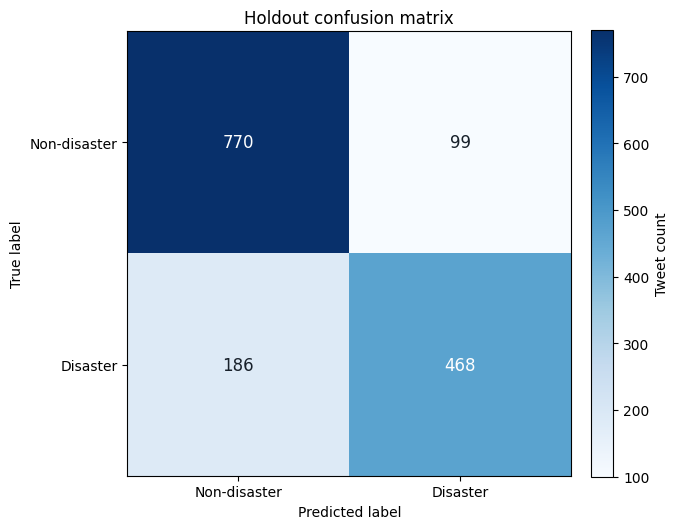

In [17]:
test_predictions = best_model.predict(test_model_input)
holdout_metrics = pd.DataFrame([{
    "model": best_candidate_name,
    "accuracy": accuracy_score(y_test, test_predictions),
    "precision": precision_score(y_test, test_predictions, zero_division=0),
    "recall": recall_score(y_test, test_predictions, zero_division=0),
    "f1": f1_score(y_test, test_predictions, zero_division=0),
}])
display(holdout_metrics.round(4))
print(classification_report(
    y_test, test_predictions,
    target_names=["Non-disaster", "Disaster"],
    zero_division=0,
))
cm = confusion_matrix(y_test, test_predictions, labels=[0, 1])
fig, ax = plt.subplots(figsize=(6.5, 5.5))
image = ax.imshow(cm, cmap="Blues")
ax.set_title("Holdout confusion matrix")
ax.set_xlabel("Predicted label")
ax.set_ylabel("True label")
ax.set_xticks([0, 1], ["Non-disaster", "Disaster"])
ax.set_yticks([0, 1], ["Non-disaster", "Disaster"])
for (row, col), value in np.ndenumerate(cm):
    ax.text(col, row, f"{value:,}", ha="center", va="center",
            color="white" if value > cm.max()/2 else "#17202a", fontsize=12)
fig.colorbar(image, ax=ax, fraction=0.046, pad=0.04, label="Tweet count")
fig.tight_layout()
plt.show()


In [18]:
model_dir = Path("models")
model_dir.mkdir(parents=True, exist_ok=True)
joblib.dump(best_model, model_dir / "disaster_tweet_classifier.joblib")
cv_results.to_csv(feature_dir / "model_cv_comparison.csv", index=False)
search_results.to_csv(feature_dir / "hyperparameter_search.csv", index=False)
holdout_metrics.to_csv(feature_dir / "holdout_metrics.csv", index=False)
print("Saved selected pipeline:", (model_dir / "disaster_tweet_classifier.joblib").resolve())


Saved selected pipeline: C:\Users\OM SHAH\Desktop\Project_7\models\disaster_tweet_classifier.joblib


 <h2><span style="color:lightblue"><b>3.2 Compare candidate models on the held-out test set</b></span></h2>


Fit the untuned Naive Bayes and Linear SVM candidates on all training rows and evaluate them alongside the tuned Logistic Regression pipeline. The test set is used only for this final comparison and generalization report; model selection remains based on cross-validation results above.

In [19]:
from sklearn.metrics import (
    average_precision_score, precision_recall_curve, roc_auc_score, roc_curve
)

models_for_test = {
    "Multinomial Naive Bayes": candidate_models["Multinomial Naive Bayes"],
    "Linear SVM": candidate_models["Linear SVM"],
    "Tuned Logistic Regression": best_model,
}

test_evaluation_rows = []
test_model_results = {}
for model_name, fitted_model in models_for_test.items():
    # GridSearchCV has already refit best_model on the full training split.
    if model_name != "Tuned Logistic Regression":
        fitted_model.fit(train_model_input, y_train)
    predictions = fitted_model.predict(test_model_input)
    if hasattr(fitted_model, "predict_proba"):
        scores = fitted_model.predict_proba(test_model_input)[:, 1]
    else:
        scores = fitted_model.decision_function(test_model_input)
    test_model_results[model_name] = {
        "model": fitted_model,
        "predictions": predictions,
        "scores": scores,
        "confusion_matrix": confusion_matrix(y_test, predictions, labels=[0, 1]),
    }
    test_evaluation_rows.append({
        "model": model_name,
        "accuracy": accuracy_score(y_test, predictions),
        "precision": precision_score(y_test, predictions, zero_division=0),
        "recall": recall_score(y_test, predictions, zero_division=0),
        "f1": f1_score(y_test, predictions, zero_division=0),
        "roc_auc": roc_auc_score(y_test, scores),
        "average_precision": average_precision_score(y_test, scores),
    })

test_model_metrics = pd.DataFrame(test_evaluation_rows).sort_values(
    "f1", ascending=False
).reset_index(drop=True)
display(test_model_metrics.round(4))
print("CV-selected deployment candidate:", "Tuned Logistic Regression")
print("CV selection basis: highest mean F1 across the candidate models; grid search then maximized precision.")


,model,accuracy,precision,recall,f1,roc_auc,average_precision
0,Linear SVM,0.8096,0.7964,0.7477,0.7713,0.8629,0.8572
1,Tuned Logistic Regression,0.8129,0.8254,0.7156,0.7666,0.8752,0.8732
2,Multinomial Naive Bayes,0.8063,0.8406,0.6774,0.7502,0.8696,0.8704


CV-selected deployment candidate: Tuned Logistic Regression
CV selection basis: highest mean F1 across the candidate models; grid search then maximized precision.


<h2><span style="color:lightblue"><b>3.3 Confusion matrices</b></span></h2>


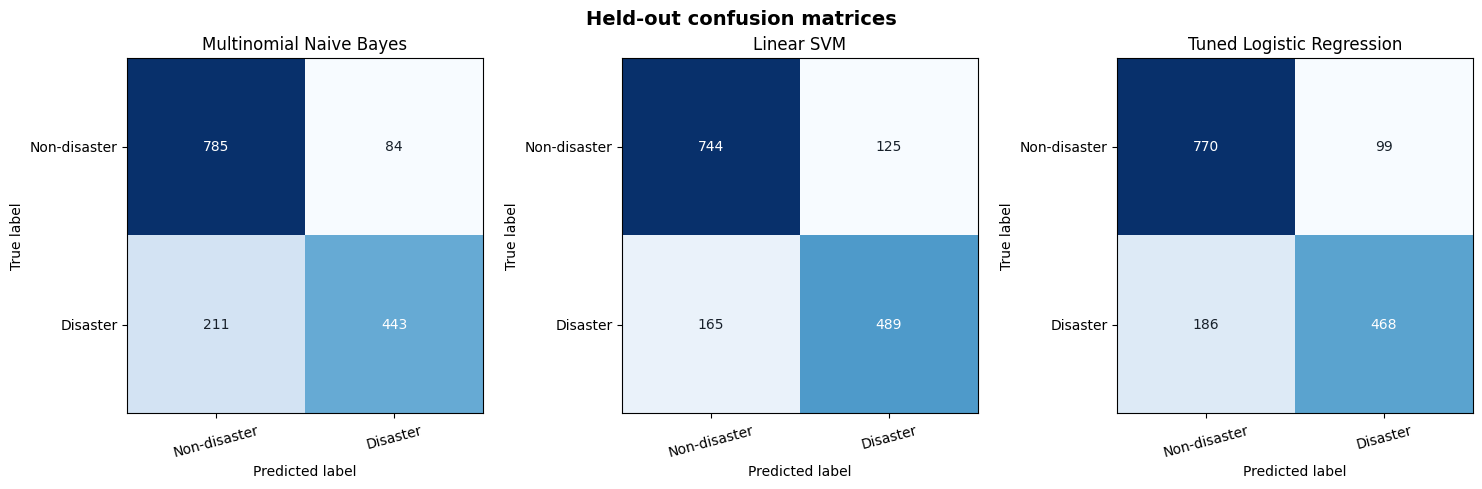

In [20]:
fig, axes = plt.subplots(1, len(test_model_results), figsize=(15, 4.8))
for ax, (model_name, result) in zip(axes, test_model_results.items()):
    cm = result["confusion_matrix"]
    image = ax.imshow(cm, cmap="Blues")
    ax.set_title(model_name)
    ax.set_xlabel("Predicted label")
    ax.set_ylabel("True label")
    ax.set_xticks([0, 1], ["Non-disaster", "Disaster"], rotation=15)
    ax.set_yticks([0, 1], ["Non-disaster", "Disaster"])
    for (row, col), value in np.ndenumerate(cm):
        ax.text(col, row, f"{value:,}", ha="center", va="center",
                color="white" if value > cm.max()/2 else "#17202a")
fig.suptitle("Held-out confusion matrices", fontsize=14, weight="bold")
fig.tight_layout()
plt.show()


<h2><span style="color:lightblue"><b>3.4 ROC and precision–recall curves</b></span></h2>


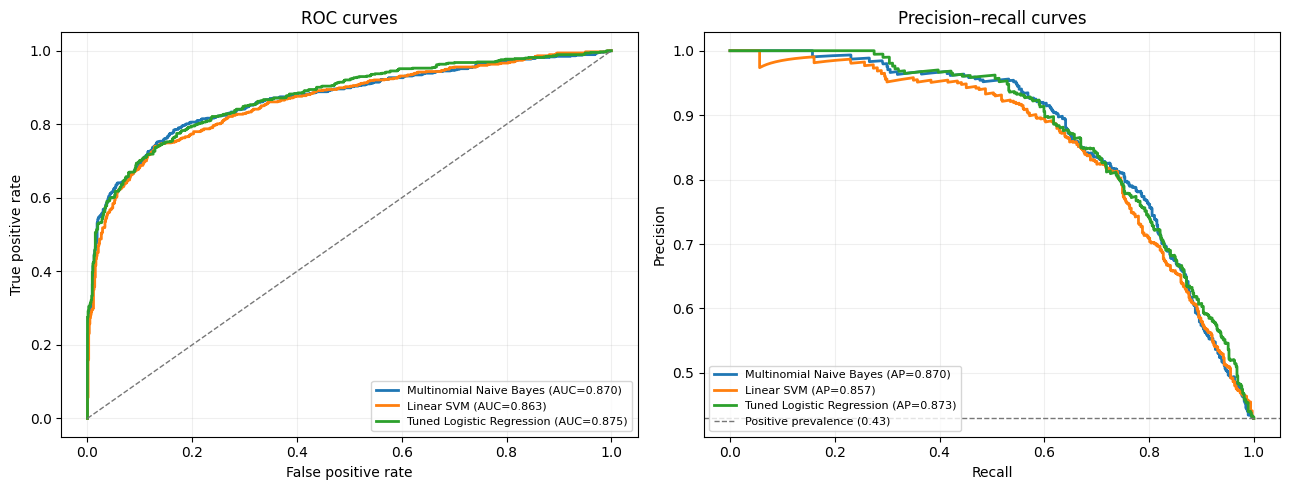

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for model_name, result in test_model_results.items():
    fpr, tpr, _ = roc_curve(y_test, result["scores"])
    roc_auc = roc_auc_score(y_test, result["scores"])
    axes[0].plot(fpr, tpr, linewidth=2, label=f"{model_name} (AUC={roc_auc:.3f})")
    precision_values, recall_values, _ = precision_recall_curve(y_test, result["scores"])
    avg_precision = average_precision_score(y_test, result["scores"])
    axes[1].plot(recall_values, precision_values, linewidth=2,
                 label=f"{model_name} (AP={avg_precision:.3f})")

axes[0].plot([0, 1], [0, 1], linestyle="--", color="#777777", linewidth=1)
axes[0].set_title("ROC curves")
axes[0].set_xlabel("False positive rate")
axes[0].set_ylabel("True positive rate")
axes[0].legend(loc="lower right", fontsize=8)
axes[0].grid(alpha=0.2)
axes[1].axhline(y_test.mean(), linestyle="--", color="#777777", linewidth=1,
                label=f"Positive prevalence ({y_test.mean():.2f})")
axes[1].set_title("Precision–recall curves")
axes[1].set_xlabel("Recall")
axes[1].set_ylabel("Precision")
axes[1].legend(loc="lower left", fontsize=8)
axes[1].grid(alpha=0.2)
fig.tight_layout()
plt.show()



 <h2><span style="color:lightblue"><b>Insights</b></span></h2>


On the held-out test set, tuned Logistic Regression scored **81.3% accuracy, 82.5% precision, 71.6% recall, 76.7% F1, and 0.875 ROC-AUC**. Linear SVM had a slightly higher test F1 (**0.771**) and recall (**0.748**); Naive Bayes had the highest test precision (**0.841**) but lower recall (**0.677**). Confusion matrices and ROC/precision–recall curves show these trade-offs.




 <h2><span style="color:lightblue"><b>Interpretation</b></span></h2>

**Interpretation:** the final Logistic Regression remains selected based on CV rather than retuning on the test set. If minimizing false alarms takes priority, review the Naive Bayes and Logistic Regression precision/recall trade-offs and choose a threshold on a separate validation set.

In [22]:
test_model_metrics.to_csv(feature_dir / "candidate_holdout_metrics.csv", index=False)
print("Saved candidate holdout metrics to", (feature_dir / "candidate_holdout_metrics.csv").resolve())


Saved candidate holdout metrics to C:\Users\OM SHAH\Desktop\Project_7\data\processed\features\candidate_holdout_metrics.csv


<h2><span style="color:lightblue"><b>3.5 Model Validation and Robustness</b></span></h2>


Validate the CV-selected Logistic Regression model against both its training data and the untouched test split. Then run controlled, label-preserving stress checks for casing/punctuation, common tweet abbreviations, and added social-media artifacts. These synthetic changes diagnose sensitivity to surface variation; they are not a substitute for a separate, independently collected dataset.


<h2><span style="color:lightblue"><b>3.5.1 Compare training, cross-validation, and test performance</b></span></h2>


A large training-to-CV gap can indicate overfitting; similar CV and test scores support generalization within this dataset. Use the saved cross-validation and holdout summaries produced in Part 3.

In [23]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

train_predictions = best_model.predict(train_model_input)
train_metrics = {
    "accuracy": accuracy_score(y_train, train_predictions),
    "precision": precision_score(y_train, train_predictions, zero_division=0),
    "recall": recall_score(y_train, train_predictions, zero_division=0),
    "f1": f1_score(y_train, train_predictions, zero_division=0),
}
cv_logistic = cv_results.loc[cv_results["model"].eq("Logistic Regression")].iloc[0]
test_logistic = holdout_metrics.iloc[0]
validation_summary = pd.DataFrame([
    {"evaluation": "Training", **train_metrics},
    {"evaluation": "5-fold CV mean", **{
        "accuracy": cv_logistic["accuracy_mean"],
        "precision": cv_logistic["precision_mean"],
        "recall": cv_logistic["recall_mean"],
        "f1": cv_logistic["f1_mean"],
    }},
    {"evaluation": "Held-out test", **{
        "accuracy": test_logistic["accuracy"],
        "precision": test_logistic["precision"],
        "recall": test_logistic["recall"],
        "f1": test_logistic["f1"],
    }},
])
display(validation_summary.round(4))
train_cv_f1_gap = train_metrics["f1"] - cv_logistic["f1_mean"]
cv_test_f1_gap = cv_logistic["f1_mean"] - test_logistic["f1"]
print(f"Train minus CV F1: {train_cv_f1_gap:+.4f}")
print(f"CV minus test F1: {cv_test_f1_gap:+.4f}")


,evaluation,accuracy,precision,recall,f1
0,Training,0.8773,0.9238,0.7788,0.8451
1,5-fold CV mean,0.8043,0.8221,0.6951,0.7531
2,Held-out test,0.8129,0.8254,0.7156,0.7666


Train minus CV F1: +0.0920
CV minus test F1: -0.0135


<h2><span style="color:lightblue"><b>3.5.2 Robustness to text variation</b></span></h2>


Evaluate the same held-out tweet labels after deterministic text perturbations. The model and threshold remain fixed. Report precision, recall, F1, and prediction agreement with the unmodified tweets for each variant.

In [24]:
ABBREVIATIONS = {
    "you": "u", "your": "ur", "are": "r", "before": "b4",
    "please": "pls", "because": "bc", "people": "ppl",
    "tonight": "2nite", "thanks": "thx", "great": "gr8",
}
def abbreviation_variant(text):
    changed = str(text)
    for word, short in ABBREVIATIONS.items():
        changed = re.sub(r"\b" + re.escape(word) + r"\b", short, changed, flags=re.IGNORECASE)
    return changed

def validation_model_input(raw_texts):
    frame = pd.DataFrame({"original_text": list(raw_texts)})
    frame["clean_text"] = frame["original_text"].map(clean_tweet)
    frame["tokens"] = frame["clean_text"].map(str.split)
    numeric = extract_structural_features(frame)
    return pd.concat([frame[["clean_text"]].reset_index(drop=True), numeric.reset_index(drop=True)], axis=1)

raw_test = test_df["original_text"].fillna("").astype(str).tolist()
text_variants = {
    "Original test text": raw_test,
    "Uppercase + punctuation": [text.upper() + " !!!" for text in raw_test],
    "Common abbreviations": [abbreviation_variant(text) for text in raw_test],
    "Added hashtag, mention, URL": [text + " #update @user https://t.co/example" for text in raw_test],
}
base_predictions = best_model.predict(test_model_input)
robustness_rows = []
for variant_name, variant_texts in text_variants.items():
    variant_input = test_model_input if variant_name == "Original test text" else validation_model_input(variant_texts)
    predictions = best_model.predict(variant_input)
    robustness_rows.append({
        "variant": variant_name,
        "accuracy": accuracy_score(y_test, predictions),
        "precision": precision_score(y_test, predictions, zero_division=0),
        "recall": recall_score(y_test, predictions, zero_division=0),
        "f1": f1_score(y_test, predictions, zero_division=0),
        "prediction_agreement_vs_original": (predictions == base_predictions).mean(),
    })
robustness_results = pd.DataFrame(robustness_rows)
display(robustness_results.round(4))


,variant,accuracy,precision,recall,f1,prediction_agreement_vs_original
0,Original test text,0.8129,0.8254,0.7156,0.7666,1.0000
1,Uppercase + punctuation,0.8089,0.8742,0.6483,0.7445,0.9462
2,Common abbreviations,0.8109,0.8222,0.7141,0.7643,0.9902
3,"Added hashtag, mention, URL",0.7781,0.7095,0.8180,0.7599,0.8772


<h2><span style="color:lightblue"><b>Validation insights and interpretation</b></span></h2>


The training F1 (**0.845**) is 9.2 percentage points above the 5-fold CV mean (**0.753**), showing the model fits the training sample better than unseen folds. The held-out test F1 (**0.767**) is close to CV, so there is no large generalization drop on this split. The test set comes from the same supplied dataset, however, so it cannot establish performance on future events, new regions, or other languages.

Common abbreviation substitutions retain **0.764 F1** and **99.0% prediction agreement** with the original tweets. Uppercase and punctuation changes retain **0.745 F1**. Adding generic hashtag, mention, and URL artifacts yields **0.760 F1**, but precision falls from **0.825** to **0.710**. This suggests that extra social-media tokens can increase false alarms under the tested perturbation. These are synthetic stress checks, not a substitute for naturally collected variation.

The model is retained because cross-validation and held-out performance are consistent. Before operational use, assess decision thresholds on a separate validation set and repeat robustness checks on newer, representative tweets.

<h2><span style="color:lightblue"><b>Part 4: Deployment and User Interface — Insights</b></span></h2>


The project includes a Streamlit entry point (`streamlit_app.py`), shared model inference logic (`predictor.py`), a themed `.streamlit/config.toml`, pinned dependencies, and hosting instructions. The interface accepts a pasted tweet, explains the input limit, returns a clear class label, and shows the model score with a calibration caveat. A clear-result action and context examples help users understand and retry the workflow.


<h2><span style="color:lightblue"><b>Interpretation</b></span></h2>

 The interface is ready as a local or cloud-deployable prototype. It has not been published to a public host; deployment still requires a connected repository and hosting account. The model should be presented as decision support for human triage, not as an automated emergency response.

<h2><span style="color:lightblue"><b>Recommendations</b></span></h2>


1. **Resolve the data-count discrepancy.** Confirm whether the intended data is the supplied 7,613-row file or another 10,000-row dataset, then refresh all reported metrics if the source changes.
2. **Validate on representative future data.** Hold out newer tweets and, where relevant, different disaster types, regions, slang, and dialects. Synthetic text edits alone cannot establish out-of-domain reliability.
3. **Set the operating threshold deliberately.** Use a separate validation set to quantify the false-alarm/missed-event trade-off, calibrate scores if probabilities will be shown, and choose a threshold with emergency-response stakeholders.
4. **Improve robustness with real examples.** Add labeled examples with hashtags, mentions, links, abbreviations, figurative language, and varying writing styles. Re-run the stress checks after retraining.
5. **Compare richer language features only when supported by data/resources.** Evaluate a stronger sentiment model or pretrained embeddings against the current TF-IDF baseline using the same leakage-safe CV procedure.
6. **Keep a human verification step.** Treat predictions as triage signals and verify urgent reports with trusted sources before action.
7. **Monitor after hosting.** Track input drift and precision/recall on newly reviewed tweets, and retrain when language or event patterns shift.

<h2><span style="color:lightblue"><b>Generalization and Text-variation validation summaries</b></span></h2>


In [25]:
validation_summary.to_csv(feature_dir / "generalization_validation.csv", index=False)
robustness_results.to_csv(feature_dir / "text_robustness_stress_test.csv", index=False)
print("Saved generalization and text-variation validation summaries to", feature_dir.resolve())


Saved generalization and text-variation validation summaries to C:\Users\OM SHAH\Desktop\Project_7\data\processed\features


<h2><span style="color:lightblue"><b>Final Conclusion</b></span></h2>


This project developed an NLP classifier to distinguish disaster-related tweets from non-disaster tweets and prepared an interactive Streamlit prototype. The supplied dataset contains **7,613 labeled tweets**, fewer than the **10,000** described in the brief; results therefore apply to the supplied sample.

The selected Logistic Regression pipeline combines word and character TF-IDF with tweet structure and lightweight lexicon-based sentiment features. On the held-out test set it achieved **81.3% accuracy, 82.5% precision, 71.6% recall, and 76.7% F1**. Cross-validation and held-out performance were broadly consistent. Robustness checks show stability to common abbreviations, with reduced precision when generic social-media artifacts are added.

The model and interface can support human review by surfacing potentially relevant posts. They are not a real-time emergency alert service, and predictions should be verified before response decisions. Cloud deployment configuration is prepared, but the app has not been published to a hosting platform.